# 05 · ANN Multiclase: Recomendación de Acción Preventiva

Este tercer modelo recibe el pronóstico de casos (que en la app vendrá del LSTM del Módulo 2), el clima y la detección de *Aedes aegypti* (que vendrá de la CNN del Módulo 1), y recomienda una de cuatro acciones de control vectorial:

| Clase | Significado |
|---|---|
| `monitoreo_normal` | No hay indicadores que exijan intervenir |
| `eliminacion_criaderos` | Lluvia y calor favorecen la reproducción del mosquito |
| `fumigacion_focalizada` | Casos por encima del umbral endémico y *Aedes aegypti* detectado |
| `alerta_sanitaria` | Casos pronosticados por encima del doble del umbral endémico |

**Sobre los datos:** `vectoria_acciones.csv` combina información real (casos, clima y canal endémico) con información simulada (la predicción del LSTM, la detección de Aedes y la etiqueta). Cada semana aparece en 5 escenarios con distinto error de predicción y distinta detección de Aedes.

## 1. Importación de librerías

In [1]:
# Librerías a utilizar

import os # Permite una interacción con el sistema operativo
import sys # Permite agregar carpetas a la ruta de búsqueda de módulos
import json # Permite guardar la configuración del modelo en un archivo
import math # Permite operaciones matemáticas básicas
import numpy as np # Permite control de arreglos y operaciones matemáticas
import pandas as pd # Permite el manejo de datos
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit # Permite dividir los datos agrupando por semana
from sklearn.preprocessing import StandardScaler # Permite estandarizar las variables numéricas
from sklearn.utils.class_weight import compute_class_weight # Permite compensar el desbalance de clases
from sklearn.metrics import classification_report, confusion_matrix # Permite la visualización del desempeño del modelo
from sklearn.metrics import roc_auc_score
from tensorflow.keras.models import Sequential # Permite creación de la red por capas
from tensorflow.keras.layers import Input, Dense, Dropout # Permite a la neurona aprender
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CosineDecay # Permite bajar la tasa de aprendizaje de forma gradual

SEED = 42
tf.keras.utils.set_random_seed(SEED) # Fija las semillas para que los resultados sean reproducibles

## 2. Carga de datos

In [2]:
base_dir = os.getcwd()
# Permite la obtención de la ruta del notebook

ruta_csv = os.path.join(base_dir, '../data/raw/Acciones/vectoria_acciones.csv')
df = pd.read_csv(ruta_csv)

df['fecha_inicio_semana'] = pd.to_datetime(df['fecha_inicio_semana'])
# Convierte la fecha a formato fecha para poder agrupar y ordenar por semana

print('Dimensiones:', df.shape)
print('Semanas distintas:', df['fecha_inicio_semana'].nunique())
print('Valores nulos en total:', int(df.isna().sum().sum()))
df.head()

Dimensiones: (2060, 12)
Semanas distintas: 412
Valores nulos en total: 0


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


El archivo tiene 2,060 filas (412 semanas × 5 escenarios) y ningún valor faltante, por lo que no hace falta imputar datos. Las columnas que usan las reglas de etiquetado son `casos_pred_4sem`, `casos_umbral_endemico`, `lluvia_14d_mm`, `temp_max` y `aegypti_detectado`; las demás (`temp_min`, `humedad`, `semana_epi`, `anio`, `escenario`) no participan en ninguna regla.

## 3. Análisis exploratorio (EDA)

### 3.1 Distribución de las clases

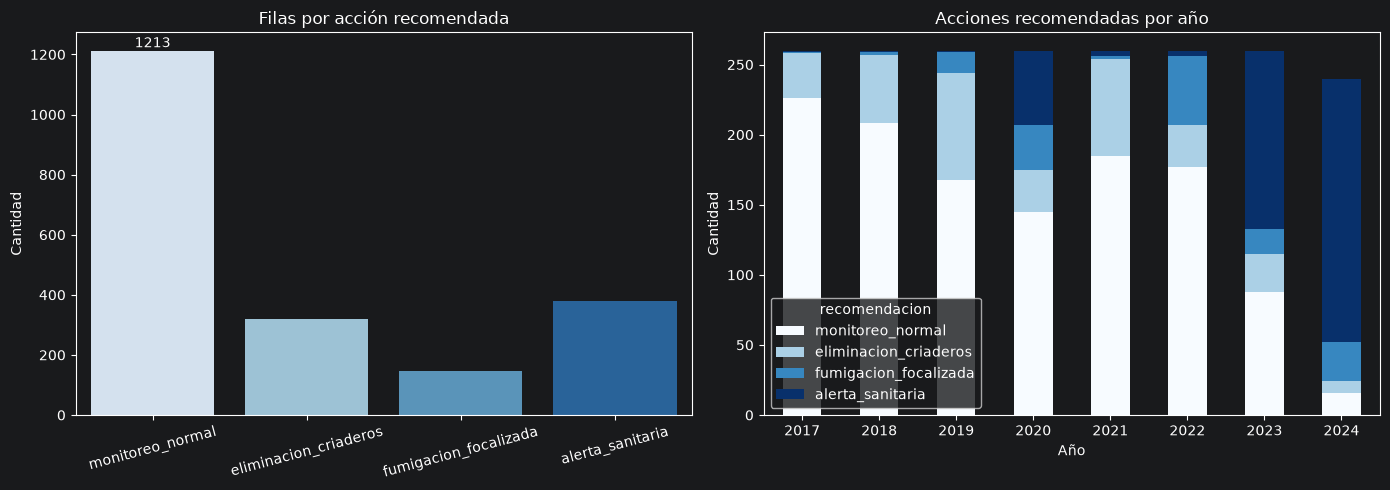

In [3]:
conteo = df['recomendacion'].value_counts()
# Cantidad de filas por acción recomendada

CLASES = ['monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada', 'alerta_sanitaria']
# Clases ordenadas de menor a mayor severidad; la posición en la lista será su número (0, 1, 2, 3)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=CLASES, y=conteo.reindex(CLASES).values, hue=CLASES, legend=False, palette='Blues', ax=ax[0])
ax[0].bar_label(ax[0].containers[0]) # Escribe la cantidad encima de cada barra
ax[0].set_title('Filas por acción recomendada')
ax[0].set_xlabel('')
ax[0].set_ylabel('Cantidad')
ax[0].tick_params(axis='x', rotation=15)
# Gráfico de la distribución de clases

por_anio = pd.crosstab(df['anio'], df['recomendacion'])[CLASES]
por_anio.plot(kind='bar', stacked=True, ax=ax[1], colormap='Blues')
ax[1].set_title('Acciones recomendadas por año')
ax[1].set_xlabel('Año')
ax[1].set_ylabel('Cantidad')
ax[1].tick_params(axis='x', rotation=0)
# Gráfico de cómo cambian las acciones a lo largo de los años

plt.tight_layout()
plt.show()

Las clases están desbalanceadas: `monitoreo_normal` concentra casi el 60 % de las filas y `fumigacion_focalizada` apenas el 7 %. Por eso más adelante se usarán *class weights* y se reportará precision y recall **por clase**, ya que el accuracy global podría ocultar un mal desempeño en las clases pequeñas.

El gráfico de la derecha muestra que las alertas sanitarias se concentran en 2020, 2023 y 2024 (años epidémicos). Esto será importante en la sección 9, donde se evalúa con un split temporal.

### 3.2 Verificación de las reglas de etiquetado

In [4]:
def aplicar_reglas(d):
    # Aplica las reglas del proyecto EN ORDEN DE PRIORIDAD (la primera que se cumple gana)
    condiciones = [
        d['casos_pred_4sem'] > 2 * d['casos_umbral_endemico'],                                  # Regla 1
        (d['casos_pred_4sem'] > d['casos_umbral_endemico']) & (d['aegypti_detectado'] == 1),    # Regla 2
        (d['lluvia_14d_mm'] > 80) & (d['temp_max'] > 27),                                       # Regla 3
    ]
    acciones = ['alerta_sanitaria', 'fumigacion_focalizada', 'eliminacion_criaderos']
    return np.select(condiciones, acciones, default='monitoreo_normal')  # Regla 4: en otro caso


df['regla'] = aplicar_reglas(df)

acuerdo = (df['regla'] == df['recomendacion']).mean()
print(f'Coincidencia entre las reglas y la etiqueta del CSV: {acuerdo:.4f}')
print(f'Filas con ruido aleatorio: {(df["regla"] != df["recomendacion"]).sum()} de {len(df)}\n')

print(classification_report(df['recomendacion'], df['regla'], labels=CLASES, digits=3))

Coincidencia entre las reglas y la etiqueta del CSV: 0.9786
Filas con ruido aleatorio: 44 de 2060

                       precision    recall  f1-score   support

     monitoreo_normal      0.976     0.996     0.986      1213
eliminacion_criaderos      0.978     0.950     0.964       321
fumigacion_focalizada      0.986     0.939     0.962       147
     alerta_sanitaria      0.986     0.963     0.975       379

             accuracy                          0.979      2060
            macro avg      0.981     0.962     0.971      2060
         weighted avg      0.979     0.979     0.979      2060



Al aplicar las reglas directamente sobre los datos se obtiene un 97.9 % de coincidencia con la etiqueta. El 2.1 % restante corresponde al ruido aleatorio que se agregó a propósito (se mencionaba un 3 %, pero parte del ruido cae en la misma clase).

**Este número es el techo realista del modelo**: ninguna ANN puede acertar de forma consistente las filas cuya etiqueta fue alterada al azar. Si nuestro modelo llegara a 100 % significaría que memorizó el ruido (sobreajuste).

### 3.3 Relación entre las variables y la acción

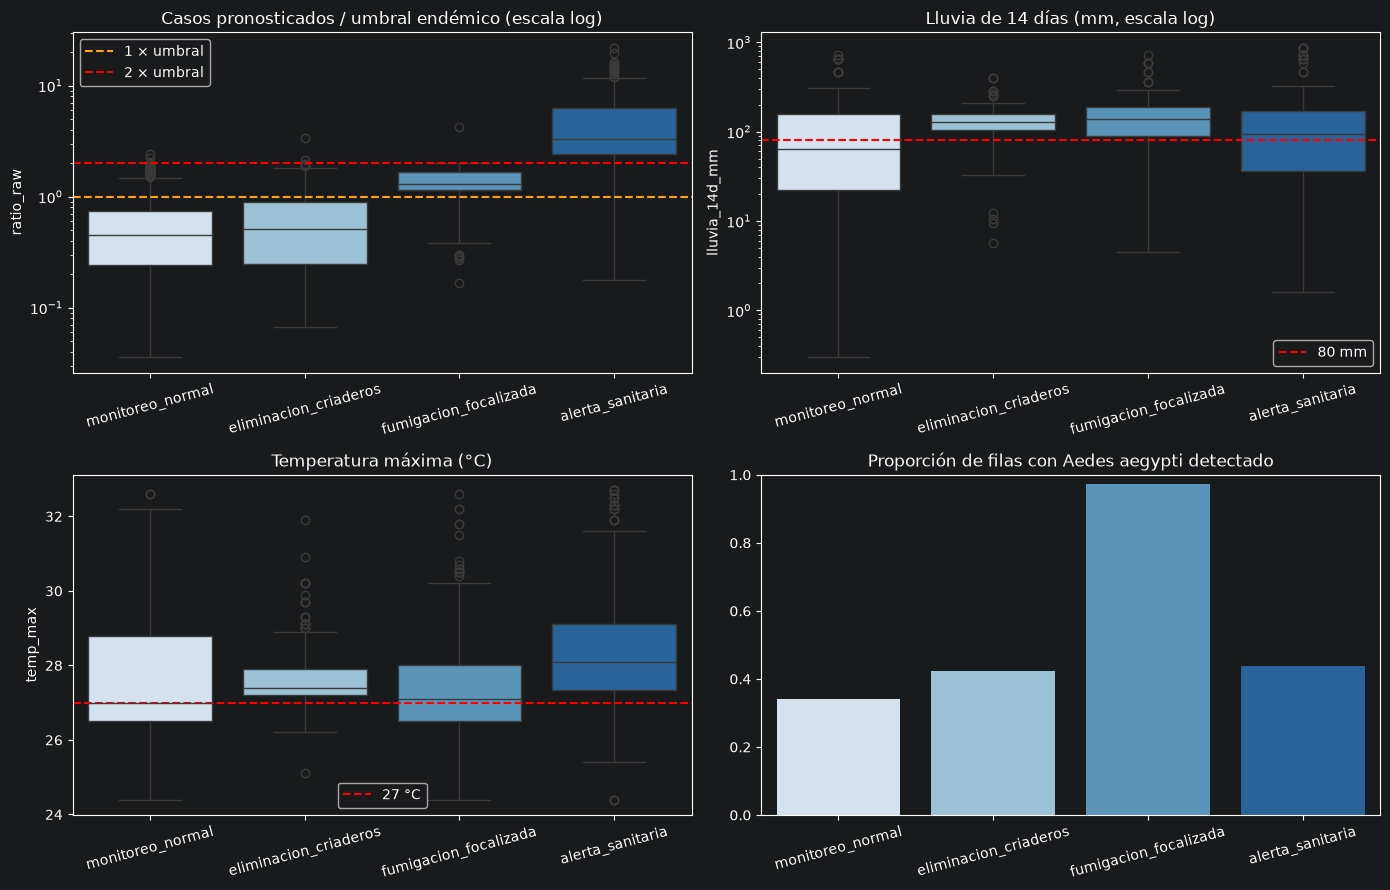

In [5]:
df['ratio_raw'] = df['casos_pred_4sem'] / df['casos_umbral_endemico']
# Razón entre casos pronosticados y umbral endémico: es lo que realmente comparan las reglas 1 y 2

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=df, x='recomendacion', y='ratio_raw', order=CLASES, hue='recomendacion', legend=False, palette='Blues', ax=ax[0, 0])
ax[0, 0].set_yscale('log')
ax[0, 0].axhline(1, color='orange', linestyle='--', label='1 × umbral')
ax[0, 0].axhline(2, color='red', linestyle='--', label='2 × umbral')
ax[0, 0].set_title('Casos pronosticados / umbral endémico (escala log)')
ax[0, 0].legend()
# Muestra dónde caen los cortes de las reglas 1 y 2

sns.boxplot(data=df, x='recomendacion', y='lluvia_14d_mm', order=CLASES, hue='recomendacion', legend=False, palette='Blues', ax=ax[0, 1])
ax[0, 1].set_yscale('log')
ax[0, 1].axhline(80, color='red', linestyle='--', label='80 mm')
ax[0, 1].set_title('Lluvia de 14 días (mm, escala log)')
ax[0, 1].legend()
# Muestra el corte de la regla 3 para la lluvia

sns.boxplot(data=df, x='recomendacion', y='temp_max', order=CLASES, hue='recomendacion', legend=False, palette='Blues', ax=ax[1, 0])
ax[1, 0].axhline(27, color='red', linestyle='--', label='27 °C')
ax[1, 0].set_title('Temperatura máxima (°C)')
ax[1, 0].legend()
# Muestra el corte de la regla 3 para la temperatura

tasa_aegypti = df.groupby('recomendacion')['aegypti_detectado'].mean().reindex(CLASES)
sns.barplot(x=tasa_aegypti.index, y=tasa_aegypti.values, hue=tasa_aegypti.index, legend=False, palette='Blues', ax=ax[1, 1])
ax[1, 1].set_title('Proporción de filas con Aedes aegypti detectado')
ax[1, 1].set_ylim(0, 1)
# Muestra que casi toda la fumigación ocurre con aegypti detectado

for a in ax.flat:
    a.set_xlabel('')
    a.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Los gráficos confirman lo que dicen las reglas: `alerta_sanitaria` tiene la razón casos/umbral más alta, `fumigacion_focalizada` casi siempre tiene Aedes detectado, y `eliminacion_criaderos` se distingue por la lluvia y la temperatura.

También se ve que la lluvia y la razón casos/umbral tienen valores extremos muy alejados (outliers). Esto se aprovechará en la preparación de los datos.

## 4. Preparación de los datos

### 4.1 Ingeniería de variables

Se hacen tres ajustes antes de entrenar:

1. **Razón casos/umbral:** las reglas 1 y 2 no comparan los casos "a secas", sino contra el umbral de esa semana. Darle la razón ya calculada le ahorra a la red tener que aprender una división.
2. **Recorte de outliers:** la razón se recorta en 4 y la lluvia en 400 mm. Más allá de esos valores la acción ya no cambia (una razón de 4 y una de 20 son igual de alerta sanitaria), pero los valores extremos comprimen la escala justo donde están los cortes importantes (1, 2 y 80 mm).
3. **Selección de variables:** se usan solo las 4 variables que intervienen en las reglas. `temp_min`, `humedad`, `semana_epi`, `anio` y `escenario` no participan en ninguna regla, así que serían ruido para la red (y en la app no se tienen disponibles).

In [6]:
CLIP_RATIO = 4.0
CLIP_LLUVIA_MM = 400.0
# Valores máximos permitidos para la razón y la lluvia

df['ratio_casos_umbral'] = df['ratio_raw'].clip(upper=CLIP_RATIO)
df['lluvia_14d_clip'] = df['lluvia_14d_mm'].clip(upper=CLIP_LLUVIA_MM)
# clip() deja igual los valores normales y limita los extremos

FEATURES = ['ratio_casos_umbral', 'lluvia_14d_clip', 'temp_max', 'aegypti_detectado']
# Variables de entrada de la red (el orden importa y se guardará junto al modelo)

print(f'Filas recortadas en la razón: {(df["ratio_raw"] > CLIP_RATIO).sum()}')
print(f'Filas recortadas en la lluvia: {(df["lluvia_14d_mm"] > CLIP_LLUVIA_MM).sum()}\n')
df[FEATURES].describe().round(2)

Filas recortadas en la razón: 153
Filas recortadas en la lluvia: 40



,ratio_casos_umbral,lluvia_14d_clip,temp_max,aegypti_detectado
count,2060.00,2060.00,2060.00,2060.00
mean,1.10,108.73,27.77,0.42
std,1.13,86.35,1.66,0.49
min,0.04,0.30,24.40,0.00
25%,0.31,32.12,26.60,0.00
50%,0.65,95.20,27.30,0.00
75%,1.42,163.35,28.70,1.00
max,4.00,400.00,32.70,1.00


### 4.2 Codificación de la etiqueta

In [7]:
mapa_clases = {nombre: i for i, nombre in enumerate(CLASES)}
print(mapa_clases)
# Diccionario de mapeo que permite ver el número asignado a cada categoría

df['y'] = df['recomendacion'].map(mapa_clases)
# Cambia el texto por su número porque la red trabaja con enteros (sparse_categorical_crossentropy)

{'monitoreo_normal': 0, 'eliminacion_criaderos': 1, 'fumigacion_focalizada': 2, 'alerta_sanitaria': 3}


### 4.3 División en entrenamiento, validación y prueba (agrupada por semana)

**Ojo:** no se puede dividir al azar por fila. Las 5 filas de una misma semana son casi idénticas, así que si unas cayeran en entrenamiento y otras en prueba, el modelo "vería" en el examen datos que ya estudió y las métricas saldrían inflados.

La solución es `GroupShuffleSplit`, que reparte **semanas completas**: las 5 filas de una semana van siempre juntas al mismo conjunto.

In [8]:
def dividir_por_semana(d, test_size, seed=SEED):
    # Divide el DataFrame en dos partes sin separar nunca las filas de una misma semana
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    idx_a, idx_b = next(gss.split(d, groups=d['fecha_inicio_semana']))
    return d.iloc[idx_a], d.iloc[idx_b]


df_trainval, df_test = dividir_por_semana(df, test_size=0.20)
# Primero se aparta el 20 % de las semanas para la prueba final

df_train, df_val = dividir_por_semana(df_trainval, test_size=0.15)
# Del resto, el 15 % se usa como validación (para vigilar el entrenamiento)

semanas_train = set(df_train['fecha_inicio_semana'])
semanas_val = set(df_val['fecha_inicio_semana'])
semanas_test = set(df_test['fecha_inicio_semana'])
assert not (semanas_train & semanas_test) and not (semanas_train & semanas_val) and not (semanas_val & semanas_test)
# Verificación: ninguna semana está en dos conjuntos a la vez

print(f'Train: {len(df_train)} filas ({len(semanas_train)} semanas)')
print(f'Val  : {len(df_val)} filas ({len(semanas_val)} semanas)')
print(f'Test : {len(df_test)} filas ({len(semanas_test)} semanas)\n')

distribucion = pd.DataFrame({
    'train': df_train['recomendacion'].value_counts(normalize=True),
    'val': df_val['recomendacion'].value_counts(normalize=True),
    'test': df_test['recomendacion'].value_counts(normalize=True),
}).reindex(CLASES)
print('Proporción de cada clase en cada conjunto:')
distribucion.round(3)

Train: 1395 filas (279 semanas)
Val  : 250 filas (50 semanas)
Test : 415 filas (83 semanas)

Proporción de cada clase en cada conjunto:


,train,val,test
recomendacion,,,
monitoreo_normal,0.612,0.500,0.564
eliminacion_criaderos,0.151,0.152,0.173
fumigacion_focalizada,0.062,0.084,0.094
alerta_sanitaria,0.174,0.264,0.169


El `assert` confirma que no hay semanas repetidas entre conjuntos. Además, las proporciones de cada clase son parecidas entre train, val y test, así que la evaluación es representativa.

### 4.4 Escalado de las variables

In [9]:
def escalar(d_train, d_val, d_test):
    # Estandariza las variables (media 0 y desviación 1) para que ninguna domine por su unidad
    escalador = StandardScaler().fit(d_train[FEATURES])
    # IMPORTANTE: el escalador aprende solo con train; val y test solo se transforman con esos valores

    def transformar(d):
        return pd.DataFrame(escalador.transform(d[FEATURES]), columns=FEATURES, index=d.index)

    return escalador, transformar(d_train), transformar(d_val), transformar(d_test)


escalador, X_train, X_val, X_test = escalar(df_train, df_val, df_test)

y_train = df_train['y'].values
y_val = df_val['y'].values
y_test = df_test['y'].values
# Etiquetas numéricas de cada conjunto

X_train.describe().loc[['mean', 'std']].round(2)

,ratio_casos_umbral,lluvia_14d_clip,temp_max,aegypti_detectado
mean,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


En el conjunto de entrenamiento todas las variables quedan con media 0 y desviación 1. Se ajusta el escalador solo con train para que la red no "espíe" información de val ni de test.

### 4.5 Guardado de los datos procesados

In [10]:
carpeta_procesados = os.path.abspath(os.path.join(base_dir, '../data/processed'))
os.makedirs(carpeta_procesados, exist_ok=True)

for nombre, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    X.to_csv(os.path.join(carpeta_procesados, f'X_{nombre}_ann.csv'), index=False)
    pd.DataFrame({'y': y}).to_csv(os.path.join(carpeta_procesados, f'y_{nombre}_ann.csv'), index=False)

print('Datos procesados guardados en:', carpeta_procesados)

Datos procesados guardados en: C:\Users\josue\Documents\VectorIA\data\processed


### 4.6 Pesos de clase

In [11]:
def calcular_pesos(y):
    # Cuanto menos frecuente es una clase, mayor es su peso en el cálculo del error
    clases = np.unique(y)
    pesos = compute_class_weight(class_weight='balanced', classes=clases, y=y)
    return dict(zip(clases.tolist(), pesos))


class_weights_dict = calcular_pesos(y_train)
print({CLASES[k]: round(v, 2) for k, v in class_weights_dict.items()})

{'monitoreo_normal': np.float64(0.41), 'eliminacion_criaderos': np.float64(1.65), 'fumigacion_focalizada': np.float64(4.01), 'alerta_sanitaria': np.float64(1.44)}


La clase más pequeña (`fumigacion_focalizada`) recibe un peso alto y la más grande (`monitoreo_normal`) uno bajo. Así un error en una clase poco frecuente "duele" más durante el entrenamiento y la red no se limita a favorecer a la clase mayoritaria.

## 5. Definición del modelo

In [12]:
EPOCHS = 200
BATCH_SIZE = 32
LR_INICIAL = 0.002
# Hiperparámetros del entrenamiento


def construir_modelo(n_entradas, n_clases, pasos_totales):
    modelo = Sequential([
        Input(shape=(n_entradas,)),
        # Cantidad de neuronas de entrada = cantidad de variables

        Dense(128, activation='relu'),
        Dropout(0.1), # Permite apagar un porcentaje de las neuronas para que encuentre distintas maneras
        Dense(64, activation='relu'),
        Dropout(0.1),
        Dense(32, activation='relu'),
        Dropout(0.1),
        # Capas ocultas

        Dense(n_clases, activation='softmax'),
        # Capa de salida múltiple: una probabilidad por acción (suman 1)
    ])

    tasa = CosineDecay(initial_learning_rate=LR_INICIAL, decay_steps=pasos_totales, alpha=0.01)
    # La tasa de aprendizaje baja poco a poco: al inicio aprende rápido y al final afina las fronteras

    modelo.compile(
        loss='sparse_categorical_crossentropy', # "Sparse" se utiliza para cuando son dígitos enteros
        optimizer=Adam(learning_rate=tasa),
        metrics=['accuracy']
    )
    return modelo


pasos_por_epoca = math.ceil(len(X_train) / BATCH_SIZE)
modelo_ejemplo = construir_modelo(len(FEATURES), len(CLASES), pasos_por_epoca * EPOCHS)
modelo_ejemplo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,108 (43.39 KB)

 Trainable params: 11,108 (43.39 KB)

 Non-trainable params: 0 (0.00 B)

La red recibe 4 variables y devuelve 4 probabilidades (una por acción). La acción recomendada es la de mayor probabilidad.

Se usó una red de 3 capas ocultas (128 → 64 → 32) con un Dropout bajo (0.1) y **sin regularización L2**. Durante las pruebas, una regularización más fuerte volvía las fronteras de decisión demasiado "suaves", y las reglas de este problema son cortes exactos (por ejemplo `temp_max > 27`), así que la red necesita fronteras nítidas.

## 6. Entrenamiento

In [13]:
def entrenar_modelo(X_tr, y_tr, X_va, y_va, pesos, epochs=EPOCHS):
    # Entrena una red nueva y devuelve el modelo junto con su historial
    pasos = math.ceil(len(X_tr) / BATCH_SIZE) * epochs
    modelo = construir_modelo(X_tr.shape[1], len(CLASES), pasos)
    historial = modelo.fit(
        x=X_tr,
        y=y_tr,
        validation_data=(X_va, y_va), # Datos que no se usan para aprender, solo para vigilar
        epochs=epochs,
        batch_size=BATCH_SIZE,
        class_weight=pesos,
        verbose=0 # Sin mensajes por época (son 200)
    )
    return modelo, historial


tf.keras.utils.set_random_seed(SEED)
modelo, historial = entrenar_modelo(X_train, y_train, X_val, y_val, class_weights_dict)

h = historial.history
print(f'Épocas: {EPOCHS}')
print(f'Accuracy  train: {h["accuracy"][-1]:.4f} | val: {h["val_accuracy"][-1]:.4f}')
print(f'Loss      train: {h["loss"][-1]:.4f} | val: {h["val_loss"][-1]:.4f}')

Épocas: 200
Accuracy  train: 0.9771 | val: 0.9200
Loss      train: 0.1059 | val: 0.4147


**¿Por qué no se usó `EarlyStopping`?** En los otros módulos se usa para detener el entrenamiento cuando `val_loss` deja de mejorar. Aquí se probó y funcionaba peor: como el 2 % de las etiquetas tiene ruido aleatorio, `val_loss` es muy irregular y el entrenamiento se detenía antes de que la red afinara las fronteras de decisión (por ejemplo, la diferencia entre 27.0 °C y 27.1 °C). Con la tasa de aprendizaje decreciente (`CosineDecay`) el entrenamiento termina de forma natural y estable.

## 7. Curvas de entrenamiento

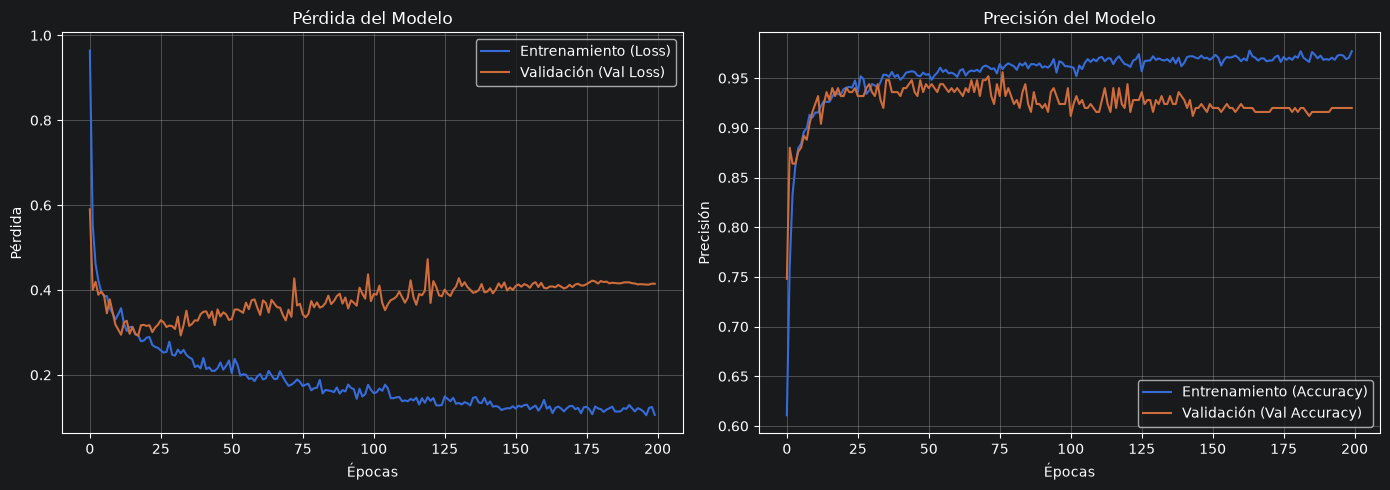

In [14]:
model_loss = pd.DataFrame(historial.history)
# Convierte el historial a DataFrame

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
# Permite mostrar los dos gráficos juntos

ax[0].plot(model_loss['loss'], label='Entrenamiento (Loss)')
ax[0].plot(model_loss['val_loss'], label='Validación (Val Loss)')
ax[0].set_title('Pérdida del Modelo')
ax[0].set_xlabel('Épocas')
ax[0].set_ylabel('Pérdida')
ax[0].legend()
ax[0].grid(True)
# Gráfico de Pérdida (Loss)

ax[1].plot(model_loss['accuracy'], label='Entrenamiento (Accuracy)')
ax[1].plot(model_loss['val_accuracy'], label='Validación (Val Accuracy)')
ax[1].set_title('Precisión del Modelo')
ax[1].set_xlabel('Épocas')
ax[1].set_ylabel('Precisión')
ax[1].legend()
ax[1].grid(True)
# Gráfico de Precisión (Accuracy)

plt.tight_layout()
plt.show()

La pérdida de entrenamiento baja de forma estable. La de validación se estabiliza y luego sube un poco, mientras el accuracy de validación (≈ 0.93) queda por debajo del de entrenamiento (≈ 0.97): hay un sobreajuste leve, esperable con pocas semanas distintas (412) y etiquetas con ruido. La evaluación final se hace con el conjunto de test, que la red nunca vio, y ahí el desempeño se mantiene alto.

Los valores exactos pueden variar un poco al reentrenar en otro equipo o versión de TensorFlow.

## 8. Evaluación del modelo

### 8.1. Métricas globales y reporte por clase

In [15]:
probabilidades = modelo.predict(X_test, verbose=0)  # probabilidad por clase (n_muestras x 4)
y_pred = np.argmax(probabilidades, axis=1)  # clase con mayor probabilidad
y_real = y_test

loss, acc = modelo.evaluate(X_test, y_test, verbose=0)
print(f'Loss: {loss:.4f} | Accuracy: {acc:.4f}\n')
# Nos da métricas globales

clases = list(range(len(CLASES)))
print(classification_report(y_real, y_pred, labels=clases, target_names=CLASES, zero_division=0, digits=3))
# Genera un reporte por clase (f1, precision, recall)

print(f'ROC-AUC (One-vs-Rest, Macro): {roc_auc_score(y_real, probabilidades, multi_class="ovr", average="macro"):.4f}')

Loss: 0.1796 | Accuracy: 0.9711

                       precision    recall  f1-score   support

     monitoreo_normal      0.971     0.996     0.983       234
eliminacion_criaderos      0.958     0.958     0.958        72
fumigacion_focalizada      1.000     0.872     0.932        39
     alerta_sanitaria      0.971     0.957     0.964        70

             accuracy                          0.971       415
            macro avg      0.975     0.946     0.959       415
         weighted avg      0.971     0.971     0.971       415

ROC-AUC (One-vs-Rest, Macro): 0.9832


En el conjunto de test (415 filas, 83 semanas) el modelo alcanza un accuracy de ≈ 0.96 y un ROC-AUC macro de ≈ 0.98. Recordemos que el techo realista es 97.9 % (sección 3.2), así que el modelo está cerca del máximo posible.

La clase más difícil es `fumigacion_focalizada`: tiene precision de 1.00 pero recall de ≈ 0.87, es decir, nunca sugiere fumigar sin motivo, pero deja pasar algo más de 1 de cada 10 casos que sí lo requerían. Como solo hay 39 filas de esa clase en test, cada error mueve mucho la métrica.

#### Verificación del umbral del proyecto (Precision y Recall ≥ 85 %)

In [16]:
reporte = classification_report(y_real, y_pred, labels=clases, target_names=CLASES, zero_division=0, output_dict=True)
tabla = pd.DataFrame(reporte).T.loc[CLASES, ['precision', 'recall', 'f1-score', 'support']]
tabla['cumple_umbral'] = (tabla['precision'] >= 0.85) & (tabla['recall'] >= 0.85)
# Una clase cumple si AMBAS métricas (precision y recall) son al menos 0.85

print(tabla.round(3))
print(f'\nPrecision macro: {reporte["macro avg"]["precision"]:.3f} | Recall macro: {reporte["macro avg"]["recall"]:.3f}')
print('¿Todas las clases cumplen el umbral de 85 %?', bool(tabla['cumple_umbral'].all()))

                       precision  recall  f1-score  support  cumple_umbral
monitoreo_normal           0.971   0.996     0.983    234.0           True
eliminacion_criaderos      0.958   0.958     0.958     72.0           True
fumigacion_focalizada      1.000   0.872     0.932     39.0           True
alerta_sanitaria           0.971   0.957     0.964     70.0           True

Precision macro: 0.975 | Recall macro: 0.946
¿Todas las clases cumplen el umbral de 85 %? True


### 8.2. Matrices de confusión

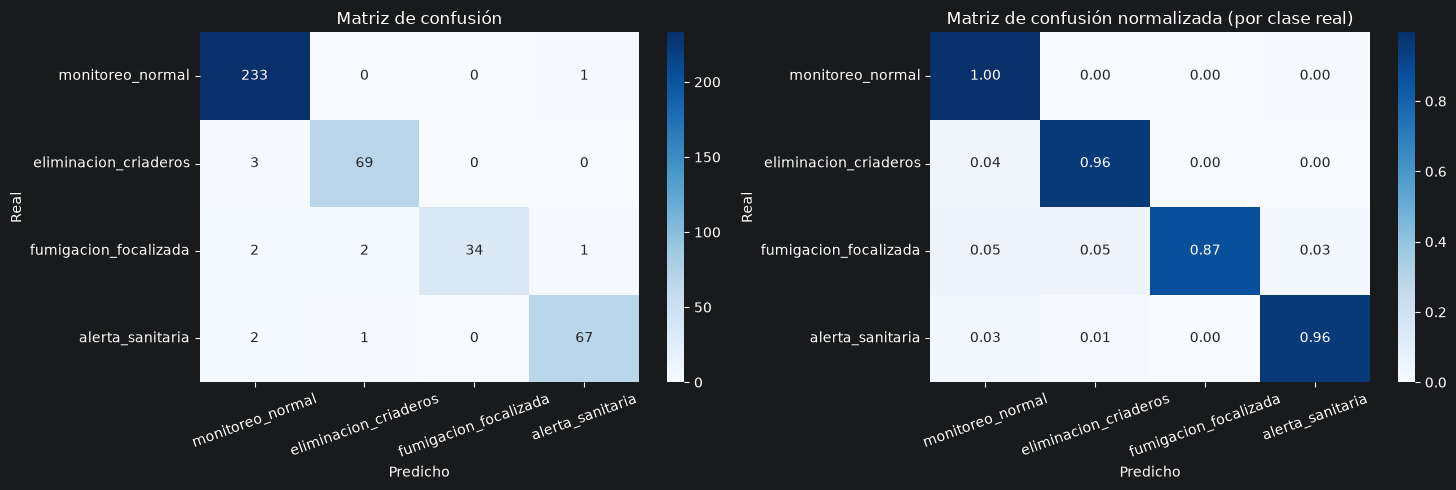

In [17]:
cm = confusion_matrix(y_real, y_pred, labels=clases)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASES, yticklabels=CLASES, ax=ax[0])
ax[0].set_title('Matriz de confusión')
ax[0].set_xlabel('Predicho')
ax[0].set_ylabel('Real')
ax[0].tick_params(axis='x', rotation=20)
# Genera una matriz de confusión con valores absolutos

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASES, yticklabels=CLASES, ax=ax[1])
ax[1].set_title('Matriz de confusión normalizada (por clase real)')
ax[1].set_xlabel('Predicho')
ax[1].set_ylabel('Real')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()
# Genera una matriz de confusión con valores estandarizados

La mayoría de los errores se da entre clases "vecinas": `monitoreo_normal` con `eliminacion_criaderos` (ambas dependen de lluvia y temperatura) y `fumigacion_focalizada` con `eliminacion_criaderos` o `alerta_sanitaria`. No hay confusiones graves entre extremos, por ejemplo casi no se confunde una alerta sanitaria con monitoreo normal.

### 8.3. Análisis de casos frontera

Como las etiquetas salen de reglas con cortes exactos, lo interesante no es el accuracy global sino **qué pasa cerca de los umbrales**. Aquí se separan los errores en dos tipos:

- **Ruido de etiqueta:** la etiqueta del CSV contradice la regla (fue alterada al azar). Ningún modelo puede acertarlas.
- **Error real del modelo:** la etiqueta sí sigue la regla, pero la red se equivocó.

In [18]:
df_eval = df_test.copy()
df_eval['pred'] = y_pred
df_eval['acierto'] = df_eval['pred'] == df_eval['y']
df_eval['regla_num'] = pd.Series(aplicar_reglas(df_eval), index=df_eval.index).map(mapa_clases)
# Acción que indicaría la regla para cada fila de test

cerca = (df_eval['ratio_raw'].between(0.9, 1.1)        # cerca del umbral endémico (1x)
         | df_eval['ratio_raw'].between(1.8, 2.2)      # cerca del doble del umbral (2x)
         | df_eval['temp_max'].between(26.8, 27.2)     # cerca de 27 °C
         | df_eval['lluvia_14d_mm'].between(70, 90))   # cerca de 80 mm
# Una fila es "frontera" si cualquiera de sus valores está cerca de un corte de las reglas

resumen = df_eval.groupby(cerca.map({True: 'Cerca de un umbral', False: 'Lejos de los umbrales'}))['acierto'].agg(['count', 'mean'])
resumen.columns = ['filas', 'accuracy']
print(resumen.round(3))

errores = df_eval[~df_eval['acierto']]
n_ruido = int((errores['y'] != errores['regla_num']).sum())
print(f'\nErrores totales en test: {len(errores)} de {len(df_eval)}')
print(f'  - Por ruido de etiqueta (irreducibles): {n_ruido}')
print(f'  - Error real del modelo: {len(errores) - n_ruido}')

                       filas  accuracy
Cerca de un umbral       151     0.947
Lejos de los umbrales    264     0.985

Errores totales en test: 12 de 415
  - Por ruido de etiqueta (irreducibles): 6
  - Error real del modelo: 6


In [19]:
errores_reales = errores[errores['y'] == errores['regla_num']].copy()
errores_reales['real'] = errores_reales['y'].map(lambda i: CLASES[i])
errores_reales['predicho'] = errores_reales['pred'].map(lambda i: CLASES[i])
# Traduce los números a nombres de clase para leer la tabla

errores_reales[['ratio_raw', 'lluvia_14d_mm', 'temp_max', 'aegypti_detectado', 'real', 'predicho']].round(2)
# Muestra los casos donde la red falló aunque la etiqueta era correcta

,ratio_raw,lluvia_14d_mm,temp_max,aegypti_detectado,real,predicho
630,1.00,131.4,27.8,1,fumigacion_focalizada,eliminacion_criaderos
633,1.00,131.4,27.8,1,fumigacion_focalizada,eliminacion_criaderos
866,1.97,68.4,29.5,0,monitoreo_normal,alerta_sanitaria
1943,2.28,322.3,26.3,0,alerta_sanitaria,monitoreo_normal
2035,1.98,190.4,27.1,1,fumigacion_focalizada,alerta_sanitaria
2038,1.76,190.4,27.1,0,eliminacion_criaderos,monitoreo_normal


Dentro del test hay 16 errores: 6 son ruido de etiqueta (irreducibles) y solo 10 son errores reales del modelo. La diferencia entre zonas es clara: lejos de los umbrales el accuracy es de ≈ 98.5 %, y cerca de ellos baja a ≈ 92 %.

La tabla de errores reales muestra el patrón esperado: casi todos tienen `temp_max` de 27.0 o 27.1 °C, o una razón casos/umbral cercana a 1 o a 2. Por ejemplo, con 27.0 °C la regla dice "no" (porque exige estrictamente `> 27`) pero la red, que dibuja fronteras continuas, a veces dice "sí".

Esto no es un defecto del modelo sino del problema: pedirle a una red que distinga 27.0 de 27.1 es pedirle precisión de décimas. Por eso la función `recomendar()` (sección 11) marca `cerca_de_umbral=True` y la app puede avisar que esos casos conviene revisarlos.

### 8.4. Predicción sobre nuevos datos
Se toman 5 filas del conjunto de test para simular una predicción en producción.

In [20]:
X_nuevos = X_test.sample(5, random_state=SEED)   # 5 filas al azar

prob_nuevos = modelo.predict(X_nuevos, verbose=0)
resultado = np.argmax(prob_nuevos, axis=1)

df_resultado = pd.DataFrame({
    'accion_predicha': [CLASES[i] for i in resultado],
    'confianza': prob_nuevos.max(axis=1).round(3),
    'accion_real': [CLASES[i] for i in df_test.loc[X_nuevos.index, 'y']]
}, index=X_nuevos.index)

print(df_resultado)

       accion_predicha  confianza       accion_real
210   monitoreo_normal      0.912  monitoreo_normal
540   monitoreo_normal      0.927  monitoreo_normal
765   monitoreo_normal      0.952  monitoreo_normal
211   monitoreo_normal      0.914  monitoreo_normal
1781  alerta_sanitaria      1.000  alerta_sanitaria


## 9. Validación adicional: split temporal

Hasta ahora se evaluó con semanas elegidas al azar. Una prueba más exigente (y más parecida al uso real) es **entrenar con el pasado y evaluar con el futuro**: entrenamiento con 2017–2022 y prueba con 2023–2024.

Es una prueba difícil a propósito, porque las alertas sanitarias casi no existen en el pasado reciente (salvo 2020) y se concentran en las epidemias de 2023–2024. La distribución de clases del test es muy distinta a la del entrenamiento.

In [22]:
df_t_trainval = df[df['anio'] <= 2022]
df_t_test = df[df['anio'] >= 2023]
# Pasado para aprender, futuro para evaluar

df_t_train, df_t_val = dividir_por_semana(df_t_trainval, test_size=0.15)
# La validación sigue siendo agrupada por semana

esc_t, X_t_train, X_t_val, X_t_test = escalar(df_t_train, df_t_val, df_t_test)
pesos_t = calcular_pesos(df_t_train['y'].values)

print('Distribución de clases (filas):')
print(pd.DataFrame({
    'train 2017-2022': df_t_train['recomendacion'].value_counts(),
    'test 2023-2024': df_t_test['recomendacion'].value_counts(),
}).reindex(CLASES).fillna(0).astype(int))

tf.keras.utils.set_random_seed(SEED)
modelo_t, _ = entrenar_modelo(X_t_train, df_t_train['y'].values, X_t_val, df_t_val['y'].values, pesos_t)

y_t_pred = np.argmax(modelo_t.predict(X_t_test, verbose=0), axis=1)
print()
print(classification_report(df_t_test['y'].values, y_t_pred, labels=clases, target_names=CLASES, zero_division=0, digits=3))

Distribución de clases (filas):
                       train 2017-2022  test 2023-2024
recomendacion                                         
monitoreo_normal                   941             104
eliminacion_criaderos              245              35
fumigacion_focalizada               84              46
alerta_sanitaria                    55             315

                       precision    recall  f1-score   support

     monitoreo_normal      0.833     0.817     0.825       104
eliminacion_criaderos      0.933     0.800     0.862        35
fumigacion_focalizada      0.702     0.717     0.710        46
     alerta_sanitaria      0.922     0.940     0.931       315

             accuracy                          0.884       500
            macro avg      0.848     0.819     0.832       500
         weighted avg      0.884     0.884     0.884       500



Con el split temporal el accuracy baja a ≈ 0.91, y las clases se comportan distinto:

- `alerta_sanitaria` se mantiene muy bien (precision y recall ≈ 0.95) aunque en el entrenamiento solo había 55 filas de esa clase. Tiene sentido: su regla (casos > 2 × umbral) es una sola comparación y la red la aprende rápido.
- `fumigacion_focalizada` **no cumple el umbral de 85 %** (precision ≈ 0.70, recall ≈ 0.71). En el test pasa a ser el 9 % de las filas (46), pero es una clase pequeña y depende de dos condiciones a la vez (casos sobre el umbral + aegypti detectado).

Conclusión para el informe: con el split por semanas el modelo cumple holgadamente el umbral, pero ante un cambio de régimen (años epidémicos que casi no aparecen en el entrenamiento) su desempeño baja, sobre todo en las clases que combinan condiciones. En producción convendría reentrenar con los datos más recientes. Además, esta evaluación usa un solo corte temporal, por lo que sirve como señal de alerta y no como una medida precisa.

## 10. Guardar el modelo

In [23]:
carpeta_modelos = os.path.abspath(os.path.join(base_dir, '../models'))
os.makedirs(carpeta_modelos, exist_ok=True)

ruta_modelo = os.path.join(carpeta_modelos, 'modelo_ann_acciones.keras')
modelo.save(ruta_modelo)
print(f'Modelo guardado en: {ruta_modelo}')
# Se guarda el modelo entrenado con el split agrupado por semana (sección 6)

config = {
    'features': FEATURES,                        # orden exacto de las variables de entrada
    'clases': CLASES,                            # nombre de cada número de clase
    'scaler_mean': escalador.mean_.tolist(),     # media de cada variable en train
    'scaler_scale': escalador.scale_.tolist(),   # desviación estándar de cada variable en train
    'clip_ratio': CLIP_RATIO,
    'clip_lluvia_mm': CLIP_LLUVIA_MM,
    'umbrales_reglas': {'factor_alerta': 2.0, 'lluvia_14d_mm': 80.0, 'temp_max_c': 27.0},
}
# La app necesita estos datos para preparar una entrada nueva igual que en el entrenamiento

ruta_config = os.path.join(carpeta_modelos, 'ann_config.json')
with open(ruta_config, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print(f'Configuración guardada en: {ruta_config}')

Modelo guardado en: C:\Users\josue\Documents\VectorIA\models\modelo_ann_acciones.keras
Configuración guardada en: C:\Users\josue\Documents\VectorIA\models\ann_config.json


## 12. Conclusiones

- **Desempeño:** la ANN alcanza ≈ 0.96 de accuracy, con precision ≥ 0.92 y recall ≥ 0.87 en las 4 clases sobre un test agrupado por semana, cumpliendo el umbral de 85 % del proyecto. El techo realista por el ruido de etiquetas es 97.9 %.
- **Lo que más ayudó:** usar la razón casos/umbral, recortar outliers, entrenar con tasa de aprendizaje decreciente y aplicar class weights. Con una ANN estándar el accuracy quedaba en 85–91 %.
- **Dónde falla:** casi todos los errores reales ocurren en casos frontera (≈ 27 °C, razón ≈ 1 o ≈ 2). Es un límite del problema, ya que las reglas son cortes exactos, y por eso `recomendar()` avisa cuando un caso está cerca de un umbral.
- **Limitación importante:** con un split temporal (entrenar 2017–2022, probar 2023–2024) el accuracy baja a ≈ 0.91 y `fumigacion_focalizada` no cumple el 85 %. El modelo es sensible a cambios en la distribución de las clases.
- **Advertencia sobre los datos:** las etiquetas provienen de reglas y la predicción de casos y la detección de Aedes son simuladas, así que estas métricas indican que la ANN aprendió las reglas del proyecto, no que su recomendación esté validada con decisiones reales de salud pública.
- **Integración:** `recomendar()` espera que `casos_pred_4sem` y `casos_umbral_endemico` estén en la misma escala (totales de 4 semanas). Hay que verificar que la salida del LSTM se convierta a esa escala.
- **Uso en la app:** la herramienta apoya la vigilancia; no diagnostica dengue en personas.